# Analyzing EEG Spectra during Anesthesia using FOOOF

**by Ryan Huang** — QLS PhD Discovery Day demo.

**Goals**
- Introduce FOOOF: separating periodic peaks from the aperiodic 1/f background in neural power spectra.
- Load an example dataset (`data.mat`) containing EEG-like recordings from two rats across 5 conditions: ketamine low/high, propofol low/high, and wake.
- Compute PSDs (Welch) for each recording.
- Preprocessing: remove line noise and band-pass
- Fit FOOOF models to spectra and compare aperiodic exponents & peaks across conditions.

**Notes**
- This notebook is written to automatically inspect the variables in `data.mat` and adapt to them (so it tolerates minor naming differences).
- The sampling frequency is **10000 Hz**. Large sampling rates are downsampled for speed and visualization.

**Data Sources**
- Arena, A., & Storm, J. (2018). Large scale multi-channel EEG in rats [Data set]. Human Brain Project Neuroinformatics Platform. https://doi.org/10.25493/4SPM-V00


## 0) Import related libraries

In [1]:
!pip install fooof


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: C:\Users\Ryan\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat

# FOOOF imports
from fooof import FOOOFGroup
from fooof.bands import Bands
from fooof.analysis import get_band_peak_fg

# FOOOF plotting functions
from fooof.plts.periodic import plot_peak_fits, plot_peak_params
from fooof.plts.aperiodic import plot_aperiodic_params, plot_aperiodic_fits
from fooof.plts.spectra import plot_spectra

C:\Users\Ryan\AppData\Local\Temp\ipykernel_125364\2572508929.py:7: DeprecationWarning: 
The `fooof` package is being deprecated and replaced by the `specparam` (spectral parameterization) package.
This version of `fooof` (1.1) is fully functional, but will not be further updated.
New projects are recommended to update to using `specparam` (see Changelog for details).
  from fooof import FOOOFGroup


In [3]:
import warnings
warnings.filterwarnings('ignore')

## 1) Load and inspect `data.mat`

This cell loads the MATLAB `.mat` file, prints the available variable names, and attempts to map them to our expected conditions:
- `ketalow`, `ketahigh`
- `prolow`, `prohigh`
- `wake`
Each can have suffix `_1` or `_2` for the two rats.


In [4]:
# Load the .mat file containing EEG recordings
data = loadmat('data.mat')

# Extract recordings for each condition
# Rat 1
ketahigh_1 = data['ketahigh_1'].flatten()
ketalow_1 = data['ketalow_1'].flatten()
prohigh_1 = data['prohigh_1'].flatten()
prolow_1 = data['prolow_1'].flatten()
wake_1 = data['wake_1'].flatten()

# Rat 2
ketahigh_2 = data['ketahigh_2'].flatten()
ketalow_2 = data['ketalow_2'].flatten()
prohigh_2 = data['prohigh_2'].flatten()
prolow_2 = data['prolow_2'].flatten()
wake_2 = data['wake_2'].flatten()

# Define recording parameters
fs = 10000  # Sampling frequency in Hz
duration = 20  # Duration in seconds
n_samples = 200000  # Total number of samples

print(f"Data loaded successfully!")
print(f"Sampling frequency: {fs} Hz")
print(f"Recording duration: {duration} seconds")
print(f"Number of samples: {n_samples}")
print(f"\nExample data shape (ketahigh_1): {ketahigh_1.shape}")

Data loaded successfully!
Sampling frequency: 10000 Hz
Recording duration: 20 seconds
Number of samples: 200000

Example data shape (ketahigh_1): (200000,)


## 2) Visualize Raw EEG Traces

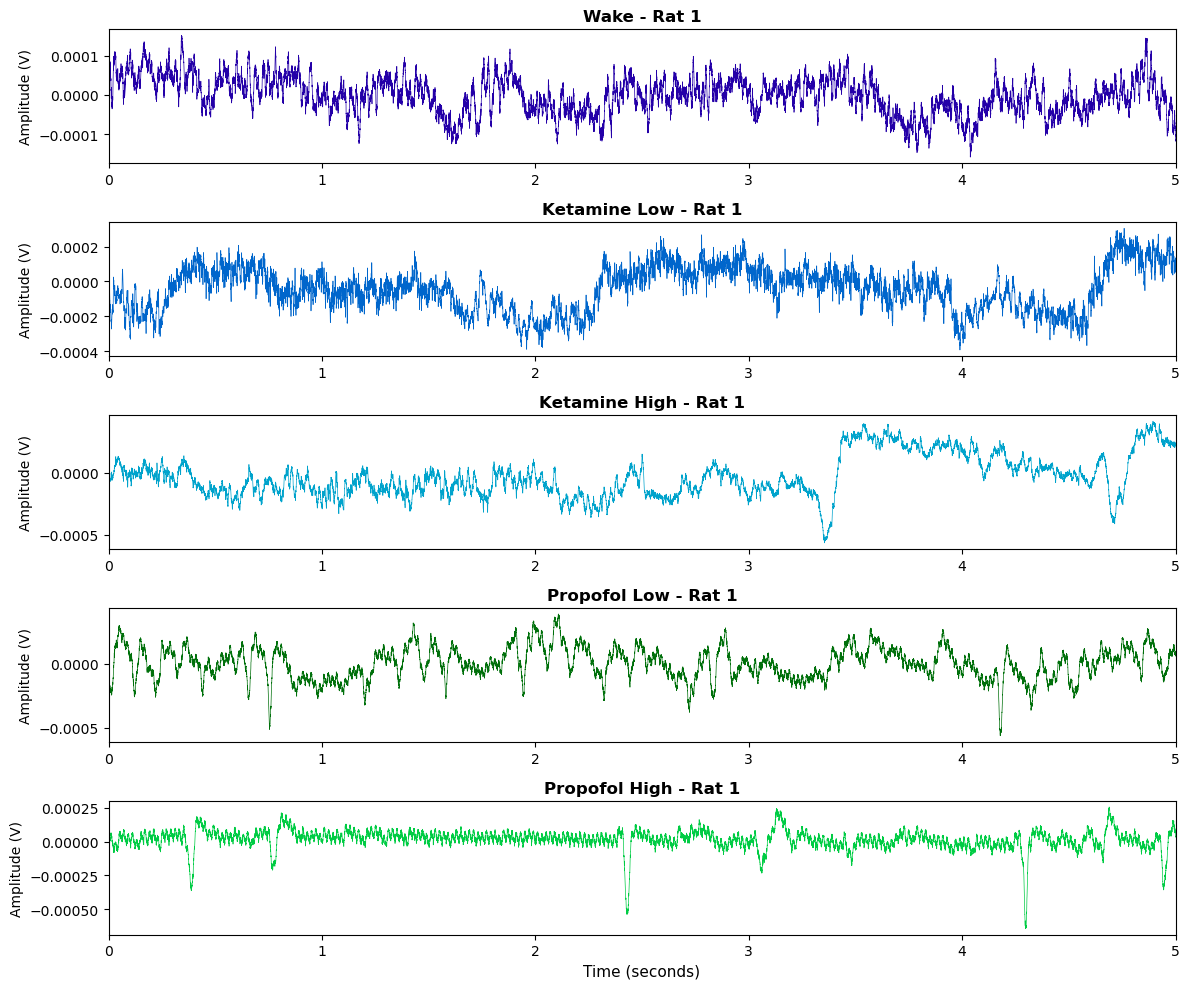

In [5]:
# Create time vector
time = np.arange(n_samples) / fs

# Plot 5 seconds of each condition for Rat 1
fig, axes = plt.subplots(5, 1, figsize=(12, 10))
conditions_rat1 = [wake_1, ketalow_1, ketahigh_1, prolow_1, prohigh_1]
condition_names = ['Wake', 'Ketamine Low', 'Ketamine High', 'Propofol Low', 'Propofol High']
colors_cond = ['#2400a8', '#0066cc', '#00a3cc', '#00700b', '#00cc44']

for idx, (eeg, name, color) in enumerate(zip(conditions_rat1, condition_names, colors_cond)):
    # Plot first 5 seconds
    axes[idx].plot(time[:50000], eeg[:50000], color=color, linewidth=0.5)
    axes[idx].set_ylabel('Amplitude (V)', fontsize=10)
    axes[idx].set_title(f'{name} - Rat 1', fontsize=12, fontweight='bold')
    axes[idx].set_xlim([0, 5])

axes[-1].set_xlabel('Time (seconds)', fontsize=11)
plt.tight_layout()
plt.show()

## 3) Compute PSDs (Welch)

We compute PSDs for:
- each individual recording (per rat)
- and a condition average PSD (average of PSDs across rats for the same condition)

We use Welch's method with a reasonably long window to get stable spectra.


In [6]:
def compute_psd(signal_data, fs, nperseg=None):
    """
    Compute Power Spectral Density using Welch's method.

    Parameters
    ----------
    signal_data : array
        EEG signal
    fs : float
        Sampling frequency
    nperseg : int, optional
        Length of each segment for Welch's method (default: 4 seconds)

    Returns
    -------
    freqs : array
        Frequency values
    psd : array
        Power spectral density values
    """
    if nperseg is None:
        nperseg = 4 * fs  # 4 second windows

    freqs, psd = signal.welch(signal_data, fs=fs, nperseg=nperseg,
                               scaling='density', average='median')
    return freqs, psd

# Compute PSDs for all conditions from both rats
print("Computing power spectral densities...")

# Rat 1
freqs, psd_wake_1 = compute_psd(wake_1, fs)
_, psd_ketalow_1 = compute_psd(ketalow_1, fs)
_, psd_ketahigh_1 = compute_psd(ketahigh_1, fs)
_, psd_prolow_1 = compute_psd(prolow_1, fs)
_, psd_prohigh_1 = compute_psd(prohigh_1, fs)

# Rat 2
_, psd_wake_2 = compute_psd(wake_2, fs)
_, psd_ketalow_2 = compute_psd(ketalow_2, fs)
_, psd_ketahigh_2 = compute_psd(ketahigh_2, fs)
_, psd_prolow_2 = compute_psd(prolow_2, fs)
_, psd_prohigh_2 = compute_psd(prohigh_2, fs)

print(f"PSD computed! Frequency resolution: {freqs[1] - freqs[0]:.4f} Hz")
print(f"Frequency range: {freqs[0]:.2f} - {freqs[-1]:.2f} Hz")


Computing power spectral densities...
PSD computed! Frequency resolution: 0.2500 Hz
Frequency range: 0.00 - 5000.00 Hz


## 4) Visualize raw PSD

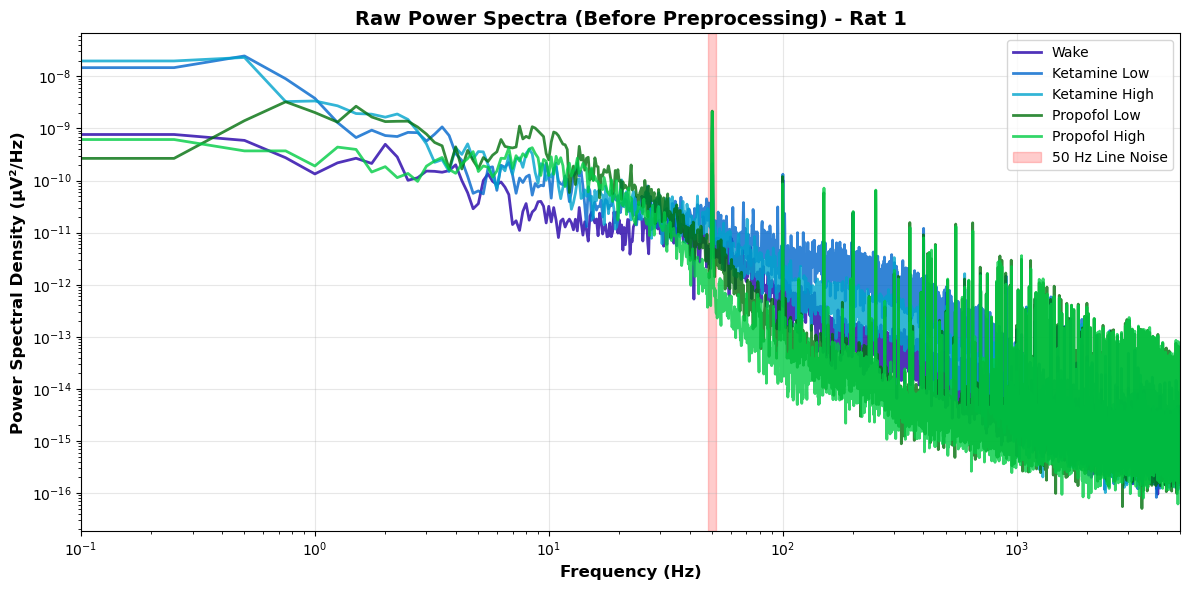

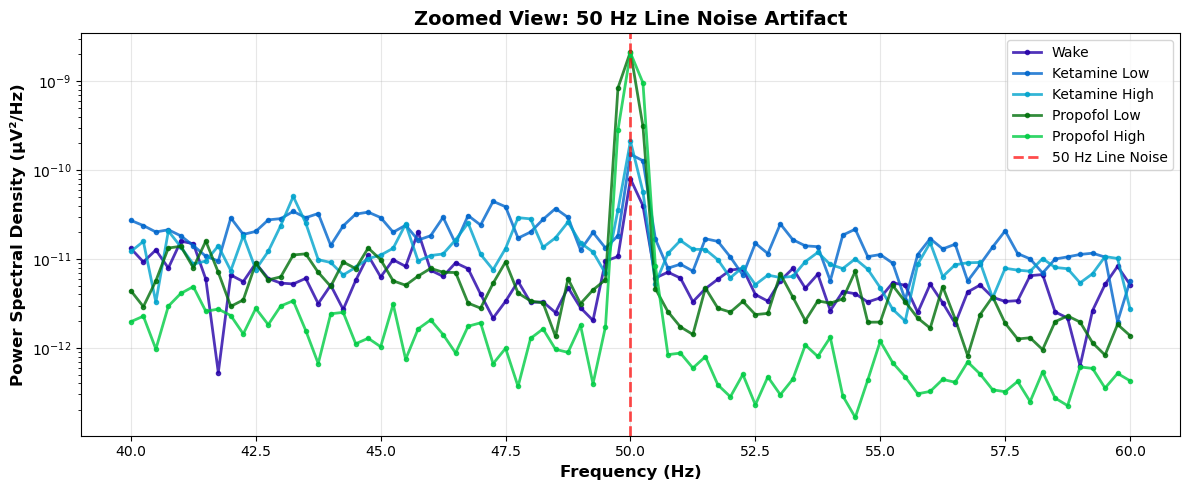


Observations from raw PSDs:
  ✓ Clear spike at 50 Hz from electrical line noise
  ✓ Very high frequency content extends beyond 90 Hz
  ✓ These artifacts need to be removed before FOOOF analysis



In [7]:
# Plot raw PSDs for all conditions (Rat 1) to see line noise and full frequency range
fig, ax = plt.subplots(figsize=(12, 6))

psds_rat1_raw = [psd_wake_1, psd_ketalow_1, psd_ketahigh_1,
                 psd_prolow_1, psd_prohigh_1]

for psd_data, name, color in zip(psds_rat1_raw, condition_names, colors_cond):
    ax.loglog(freqs, psd_data, label=name, color=color, linewidth=2, alpha=0.8)

# Highlight the 50 Hz line noise region
ax.axvspan(48, 52, alpha=0.2, color='red', label='50 Hz Line Noise')

ax.set_xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
ax.set_ylabel('Power Spectral Density (μV²/Hz)', fontsize=12, fontweight='bold')
ax.set_title('Raw Power Spectra (Before Preprocessing) - Rat 1', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim([0.1, 5000])  # Show full frequency range
plt.tight_layout()
plt.show()

# Zoom in on the line noise region to see it more clearly
fig, ax = plt.subplots(figsize=(12, 5))

for psd_data, name, color in zip(psds_rat1_raw, condition_names, colors_cond):
    # Find indices for 40-60 Hz range
    zoom_idx = (freqs >= 40) & (freqs <= 60)
    ax.semilogy(freqs[zoom_idx], psd_data[zoom_idx], label=name,
                color=color, linewidth=2, alpha=0.8, marker='o', markersize=3)

# Highlight the 50 Hz spike
ax.axvline(50, color='red', linestyle='--', linewidth=2, alpha=0.7, label='50 Hz Line Noise')

ax.set_xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
ax.set_ylabel('Power Spectral Density (μV²/Hz)', fontsize=12, fontweight='bold')
ax.set_title('Zoomed View: 50 Hz Line Noise Artifact', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nObservations from raw PSDs:")
print("  ✓ Clear spike at 50 Hz from electrical line noise")
print("  ✓ Very high frequency content extends beyond 90 Hz")
print("  ✓ These artifacts need to be removed before FOOOF analysis\n")

## 5) Preprocess PSDs


In [8]:
def preprocess_psd(freqs, psd, fs=10000, line_noise=50, freq_range=[0.1, 90]):
    """
    Pre-process PSD by removing line noise and band-pass filtering.

    Parameters
    ----------
    freqs : array
        Frequency values
    psd : array
        Power spectral density values
    fs : float
        Sampling frequency
    line_noise : float
        Line noise frequency to interpolate (default: 50 Hz)
    freq_range : list
        Frequency range to keep [low, high] in Hz

    Returns
    -------
    freqs_clean : array
        Cleaned frequency values
    psd_clean : array
        Cleaned power spectral density values
    """
    # Step 1: Remove line noise at 50 Hz by interpolation
    # Define a window around 50 Hz to interpolate (±2 Hz)
    noise_window = 2  # Hz
    noise_mask = (freqs >= line_noise - noise_window) & (freqs <= line_noise + noise_window)

    # Find indices outside the noise window for interpolation
    clean_idx = ~noise_mask

    # Interpolate across the line noise frequency
    psd_interp = np.copy(psd)
    psd_interp[noise_mask] = np.interp(
        freqs[noise_mask],
        freqs[clean_idx],
        psd[clean_idx]
    )

    # Step 2: Band-pass filter - keep only frequencies in specified range
    freq_mask = (freqs >= freq_range[0]) & (freqs <= freq_range[1])
    freqs_clean = freqs[freq_mask]
    psd_clean = psd_interp[freq_mask]

    return freqs_clean, psd_clean

# Apply preprocessing to all PSDs
print("Applying PSD preprocessing:")
print("  1. Removing line noise at 50 Hz (±2 Hz interpolation)")
print("  2. Band-pass filtering: 0.1 - 90 Hz\n")

# Rat 1
freqs_clean, psd_wake_1_clean = preprocess_psd(freqs, psd_wake_1)
_, psd_ketalow_1_clean = preprocess_psd(freqs, psd_ketalow_1)
_, psd_ketahigh_1_clean = preprocess_psd(freqs, psd_ketahigh_1)
_, psd_prolow_1_clean = preprocess_psd(freqs, psd_prolow_1)
_, psd_prohigh_1_clean = preprocess_psd(freqs, psd_prohigh_1)

# Rat 2
_, psd_wake_2_clean = preprocess_psd(freqs, psd_wake_2)
_, psd_ketalow_2_clean = preprocess_psd(freqs, psd_ketalow_2)
_, psd_ketahigh_2_clean = preprocess_psd(freqs, psd_ketahigh_2)
_, psd_prolow_2_clean = preprocess_psd(freqs, psd_prolow_2)
_, psd_prohigh_2_clean = preprocess_psd(freqs, psd_prohigh_2)

print(f"Preprocessing complete!")
print(f"New frequency range: {freqs_clean[0]:.2f} - {freqs_clean[-1]:.2f} Hz")


Applying PSD preprocessing:
  1. Removing line noise at 50 Hz (±2 Hz interpolation)
  2. Band-pass filtering: 0.1 - 90 Hz

Preprocessing complete!
New frequency range: 0.25 - 90.00 Hz


## 6) Visualize Cleaned PSDs (After Preprocessing)

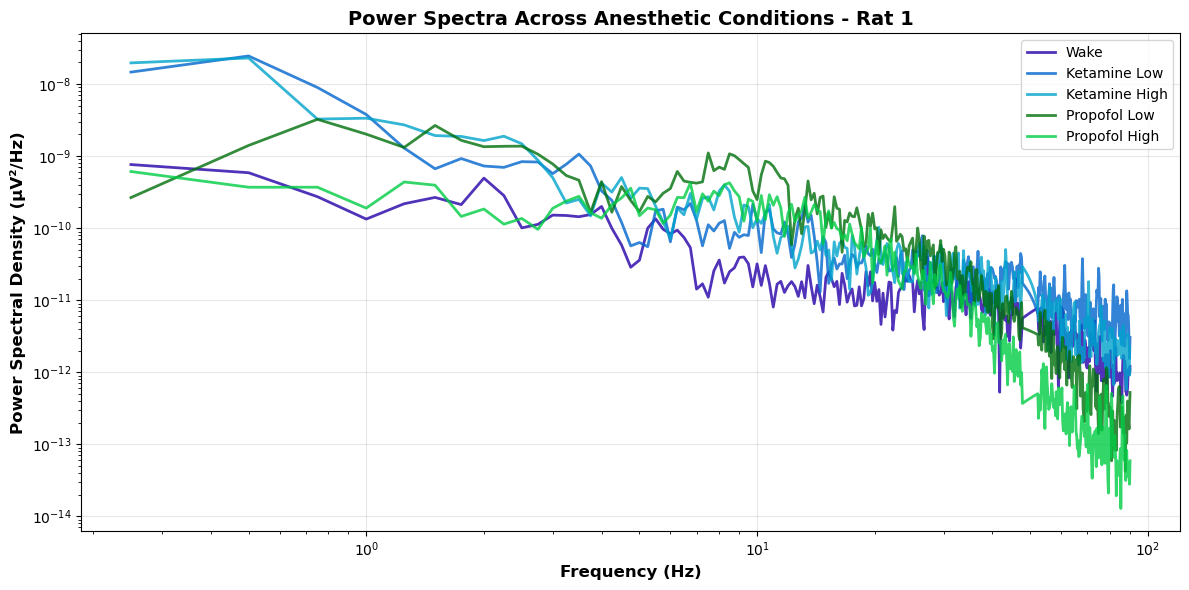

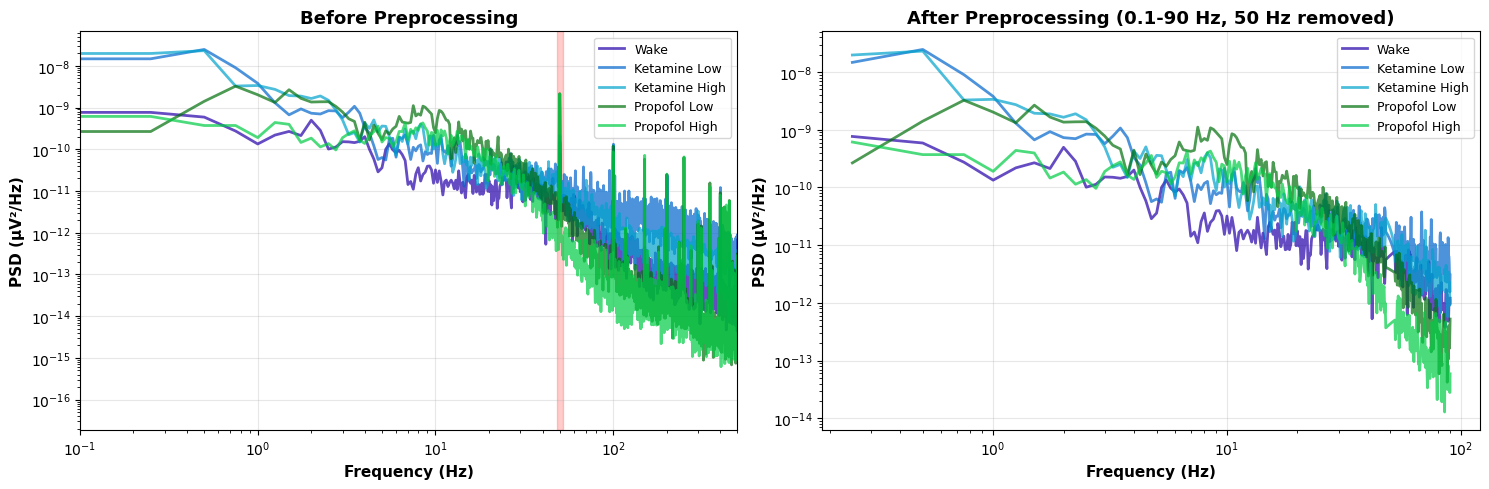


✓ Preprocessing successfully removed 50 Hz line noise and restricted to 0.1-90 Hz
✓ PSDs are now ready for FOOOF parameterization



In [9]:
# Plot cleaned PSDs for all conditions (Rat 1)
fig, ax = plt.subplots(figsize=(12, 6))

psds_rat1 = [psd_wake_1_clean, psd_ketalow_1_clean, psd_ketahigh_1_clean,
             psd_prolow_1_clean, psd_prohigh_1_clean]

for psd_data, name, color in zip(psds_rat1, condition_names, colors_cond):
    ax.loglog(freqs_clean, psd_data, label=name, color=color, linewidth=2, alpha=0.8)

ax.set_xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
ax.set_ylabel('Power Spectral Density (μV²/Hz)', fontsize=12, fontweight='bold')
ax.set_title('Power Spectra Across Anesthetic Conditions - Rat 1', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Create a comparison plot: Before vs After preprocessing
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Before preprocessing
for psd_data, name, color in zip(psds_rat1_raw, condition_names, colors_cond):
    axes[0].loglog(freqs, psd_data, label=name, color=color, linewidth=2, alpha=0.7)
axes[0].axvspan(48, 52, alpha=0.2, color='red', zorder=0)
axes[0].set_xlabel('Frequency (Hz)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('PSD (μV²/Hz)', fontsize=11, fontweight='bold')
axes[0].set_title('Before Preprocessing', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim([0.1, 500])

# After preprocessing
for psd_data, name, color in zip(psds_rat1, condition_names, colors_cond):
    axes[1].loglog(freqs_clean, psd_data, label=name, color=color, linewidth=2, alpha=0.7)
axes[1].set_xlabel('Frequency (Hz)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('PSD (μV²/Hz)', fontsize=11, fontweight='bold')
axes[1].set_title('After Preprocessing (0.1-90 Hz, 50 Hz removed)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Preprocessing successfully removed 50 Hz line noise and restricted to 0.1-90 Hz")
print("✓ PSDs are now ready for FOOOF parameterization\n")

## 7) Organize Data for Group Comparison

In [10]:
# Organize data by condition (5 separate conditions, both rats per condition)

# Ketamine Low (both rats)
ketalow_psds = np.array([
    psd_ketalow_1_clean,
    psd_ketalow_2_clean
])

# Ketamine High (both rats)
ketahigh_psds = np.array([
    psd_ketahigh_1_clean,
    psd_ketahigh_2_clean
])

# Propofol Low (both rats)
prolow_psds = np.array([
    psd_prolow_1_clean,
    psd_prolow_2_clean
])

# Propofol High (both rats)
prohigh_psds = np.array([
    psd_prohigh_1_clean,
    psd_prohigh_2_clean
])

# Wake (both rats)
wake_psds = np.array([
    psd_wake_1_clean,
    psd_wake_2_clean
])

print(f"Data organized into 5 conditions (2 rats each):")
print(f"  Ketamine Low: {ketalow_psds.shape[0]} recordings")
print(f"  Ketamine High: {ketahigh_psds.shape[0]} recordings")
print(f"  Propofol Low: {prolow_psds.shape[0]} recordings")
print(f"  Propofol High: {prohigh_psds.shape[0]} recordings")
print(f"  Wake: {wake_psds.shape[0]} recordings")

Data organized into 5 conditions (2 rats each):
  Ketamine Low: 2 recordings
  Ketamine High: 2 recordings
  Propofol Low: 2 recordings
  Propofol High: 2 recordings
  Wake: 2 recordings


## 8) Fit FOOOF models to spectra

We'll:
- Fit FOOOF to each individual PSD (1–90 Hz)
- Extract aperiodic exponents and peak parameters

**Parameters**
- Frequency range: 1–90 Hz
- Max peaks: 6 (safe default)


In [11]:
# Initialize FOOOFGroup objects for each condition
fg_ketalow = FOOOFGroup(peak_width_limits=[1, 12],
                         max_n_peaks=6,
                         min_peak_height=0.1,
                         verbose=False)

fg_ketahigh = FOOOFGroup(peak_width_limits=[1, 12],
                          max_n_peaks=6,
                          min_peak_height=0.1,
                          verbose=False)

fg_prolow = FOOOFGroup(peak_width_limits=[1, 12],
                        max_n_peaks=6,
                        min_peak_height=0.1,
                        verbose=False)

fg_prohigh = FOOOFGroup(peak_width_limits=[1, 12],
                         max_n_peaks=6,
                         min_peak_height=0.1,
                         verbose=False)

fg_wake = FOOOFGroup(peak_width_limits=[1, 12],
                      max_n_peaks=6,
                      min_peak_height=0.1,
                      verbose=False)

# Define the frequency range for FOOOF fitting (1-90 Hz is typical for EEG)
fit_range = [1, 90]

print(f"Fitting FOOOF models...")
print(f"Frequency range for fitting: {fit_range[0]} - {fit_range[1]} Hz\n")

# Fit the models
fg_ketalow.fit(freqs_clean, ketalow_psds, fit_range)
fg_ketahigh.fit(freqs_clean, ketahigh_psds, fit_range)
fg_prolow.fit(freqs_clean, prolow_psds, fit_range)
fg_prohigh.fit(freqs_clean, prohigh_psds, fit_range)
fg_wake.fit(freqs_clean, wake_psds, fit_range)

print("FOOOF fitting complete!")
print(f"\nModel fit quality (R²):")
print(f"  Ketamine Low: {np.mean([res.r_squared for res in fg_ketalow]):.3f} ± {np.std([res.r_squared for res in fg_ketalow]):.3f}")
print(f"  Ketamine High: {np.mean([res.r_squared for res in fg_ketahigh]):.3f} ± {np.std([res.r_squared for res in fg_ketahigh]):.3f}")
print(f"  Propofol Low: {np.mean([res.r_squared for res in fg_prolow]):.3f} ± {np.std([res.r_squared for res in fg_prolow]):.3f}")
print(f"  Propofol High: {np.mean([res.r_squared for res in fg_prohigh]):.3f} ± {np.std([res.r_squared for res in fg_prohigh]):.3f}")
print(f"  Wake: {np.mean([res.r_squared for res in fg_wake]):.3f} ± {np.std([res.r_squared for res in fg_wake]):.3f}")


Fitting FOOOF models...
Frequency range for fitting: 1 - 90 Hz

FOOOF fitting complete!

Model fit quality (R²):
  Ketamine Low: 0.874 ± 0.020
  Ketamine High: 0.913 ± 0.020
  Propofol Low: 0.943 ± 0.007
  Propofol High: 0.949 ± 0.007
  Wake: 0.899 ± 0.022


## 9) Visualize FOOOF Model Fits

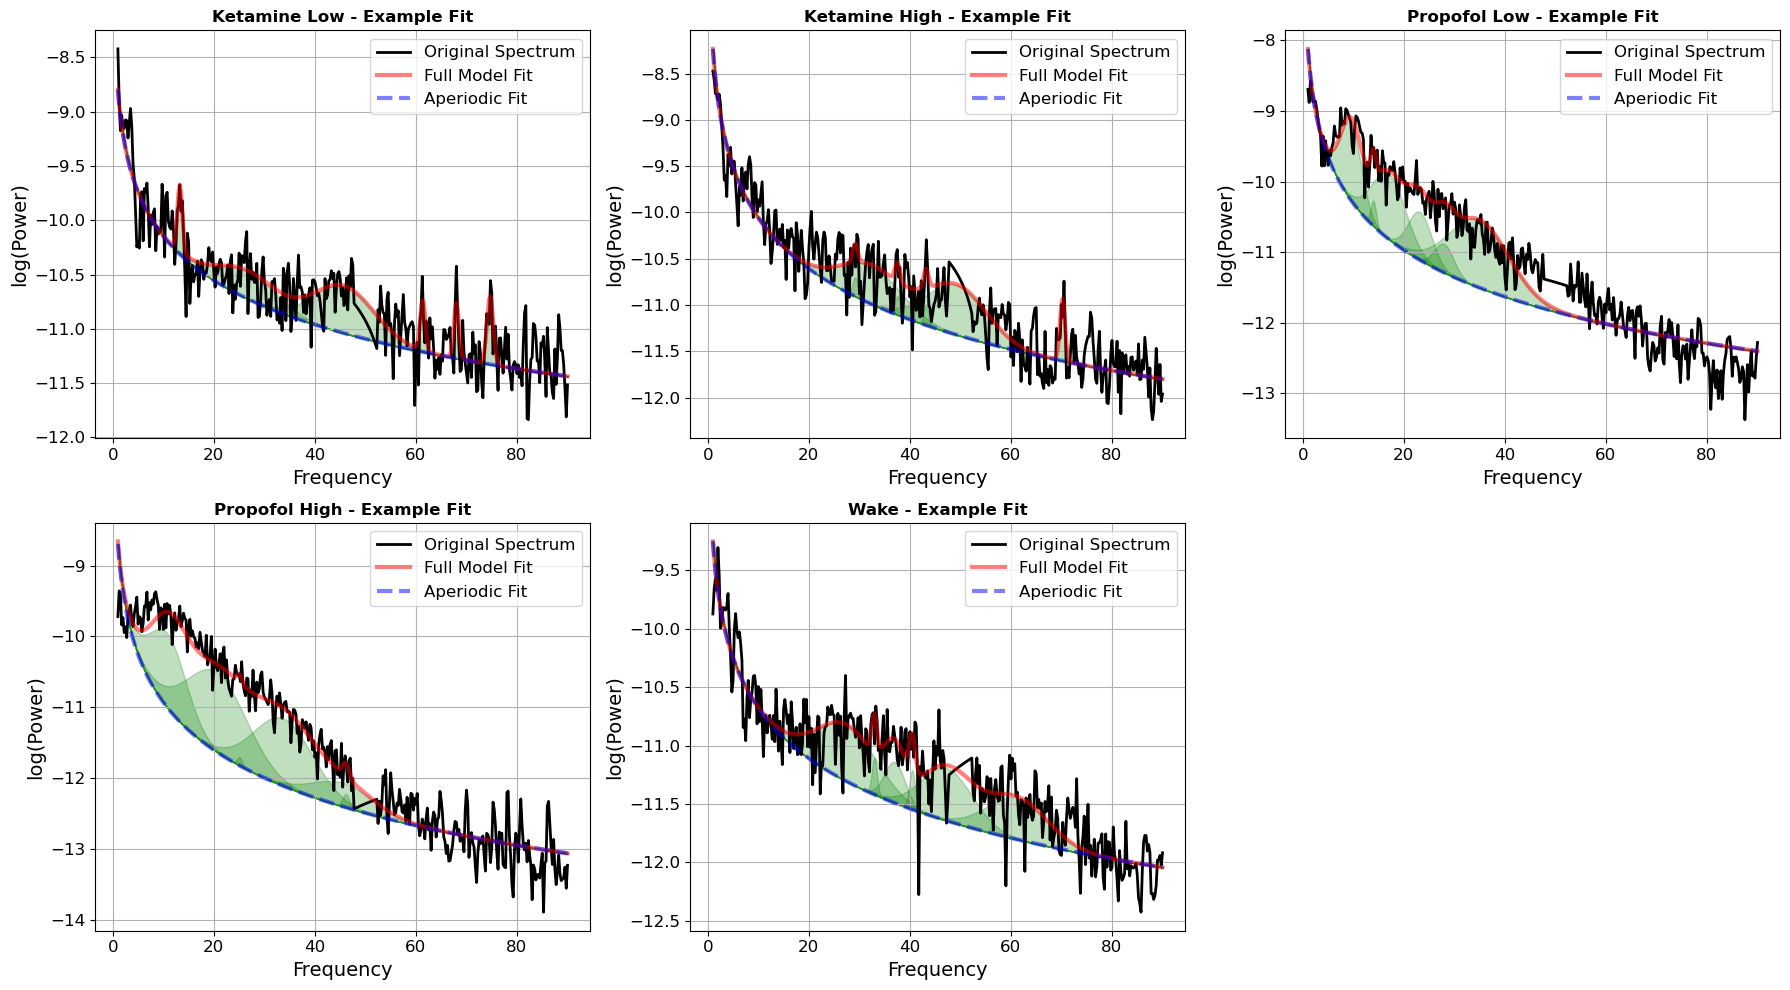

In [12]:
# Set up colors and labels for all 5 conditions
colors = ['#0066cc', '#00a3cc', '#00700b', '#00cc44', '#cc6600']
labels = ['Ketamine Low', 'Ketamine High', 'Propofol Low', 'Propofol High', 'Wake']

# Plot example fits from each condition using FOOOF's built-in plot method
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

fg_list = [fg_ketalow, fg_ketahigh, fg_prolow, fg_prohigh, fg_wake]

for idx, (fg, label, color) in enumerate(zip(fg_list, labels, colors)):
    # Get the first model fit and use FOOOF's plot method
    fg.get_fooof(0).plot(ax=axes[idx], plot_peaks='shade', add_legend=True)
    axes[idx].set_title(f'{label} - Example Fit', fontsize=12, fontweight='bold')

# Remove the empty 6th subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 10) Extract and Compare Aperiodic Parameters

- Extract aperiodic parameters (offset and exponent)
- The exponent reflects the "1/f slope" of neural activity
- The offset reflects overall power

In [13]:
aps_ketalow = fg_ketalow.get_params('aperiodic_params')
aps_ketahigh = fg_ketahigh.get_params('aperiodic_params')
aps_prolow = fg_prolow.get_params('aperiodic_params')
aps_prohigh = fg_prohigh.get_params('aperiodic_params')
aps_wake = fg_wake.get_params('aperiodic_params')

print("\n" + "="*70)
print("APERIODIC PARAMETERS")
print("="*70)
print("\nThe aperiodic component represents the '1/f' background of neural activity.")
print("- Offset: Overall power level")
print("- Exponent: Slope of the 1/f decay (higher = steeper slope)\n")

print("Ketamine Low:")
print(f"  Offset: {aps_ketalow[:, 0].mean():.3f} ± {aps_ketalow[:, 0].std():.3f}")
print(f"  Exponent: {aps_ketalow[:, 1].mean():.3f} ± {aps_ketalow[:, 1].std():.3f}")

print("\nKetamine High:")
print(f"  Offset: {aps_ketahigh[:, 0].mean():.3f} ± {aps_ketahigh[:, 0].std():.3f}")
print(f"  Exponent: {aps_ketahigh[:, 1].mean():.3f} ± {aps_ketahigh[:, 1].std():.3f}")

print("\nPropofol Low:")
print(f"  Offset: {aps_prolow[:, 0].mean():.3f} ± {aps_prolow[:, 0].std():.3f}")
print(f"  Exponent: {aps_prolow[:, 1].mean():.3f} ± {aps_prolow[:, 1].std():.3f}")

print("\nPropofol High:")
print(f"  Offset: {aps_prohigh[:, 0].mean():.3f} ± {aps_prohigh[:, 0].std():.3f}")
print(f"  Exponent: {aps_prohigh[:, 1].mean():.3f} ± {aps_prohigh[:, 1].std():.3f}")

print("\nWake:")
print(f"  Offset: {aps_wake[:, 0].mean():.3f} ± {aps_wake[:, 0].std():.3f}")
print(f"  Exponent: {aps_wake[:, 1].mean():.3f} ± {aps_wake[:, 1].std():.3f}")


APERIODIC PARAMETERS

The aperiodic component represents the '1/f' background of neural activity.
- Offset: Overall power level
- Exponent: Slope of the 1/f decay (higher = steeper slope)

Ketamine Low:
  Offset: -8.776 ± 0.021
  Exponent: 1.427 ± 0.077

Ketamine High:
  Offset: -8.198 ± 0.035
  Exponent: 1.882 ± 0.056

Propofol Low:
  Offset: -8.089 ± 0.030
  Exponent: 2.223 ± 0.031

Propofol High:
  Offset: -8.455 ± 0.243
  Exponent: 2.322 ± 0.089

Wake:
  Offset: -9.181 ± 0.071
  Exponent: 1.473 ± 0.045


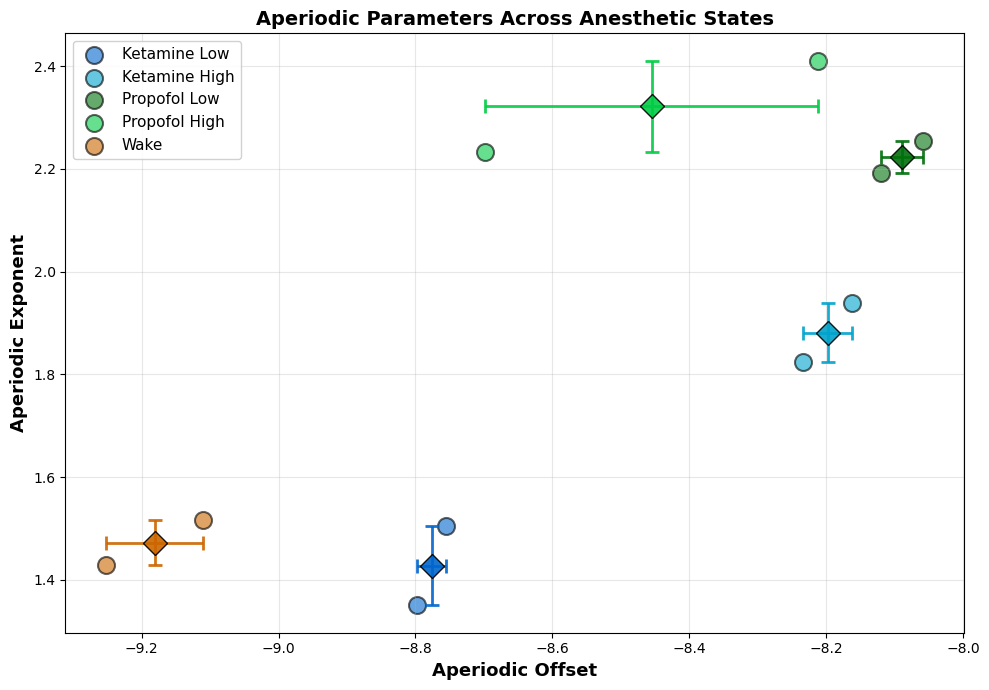

In [14]:
# Plot 1: Scatter plot of Offset vs Exponent
fig, ax = plt.subplots(figsize=(10, 7))

aps_list = [aps_ketalow, aps_ketahigh, aps_prolow, aps_prohigh, aps_wake]

for aps, label, color in zip(aps_list, labels, colors):
    # Plot individual points
    ax.scatter(aps[:, 0], aps[:, 1], s=150, alpha=0.6, color=color,
               edgecolors='black', linewidth=1.5, label=label)

    # Plot mean with error bars
    mean_offset = aps[:, 0].mean()
    mean_exponent = aps[:, 1].mean()
    std_offset = aps[:, 0].std()
    std_exponent = aps[:, 1].std()

    ax.errorbar(mean_offset, mean_exponent, xerr=std_offset, yerr=std_exponent,
                fmt='D', markersize=12, color=color, markeredgecolor='black',
                linewidth=2, capsize=5, capthick=2, alpha=0.9)

ax.set_xlabel('Aperiodic Offset', fontsize=13, fontweight='bold')
ax.set_ylabel('Aperiodic Exponent', fontsize=13, fontweight='bold')
ax.set_title('Aperiodic Parameters Across Anesthetic States', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best', framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

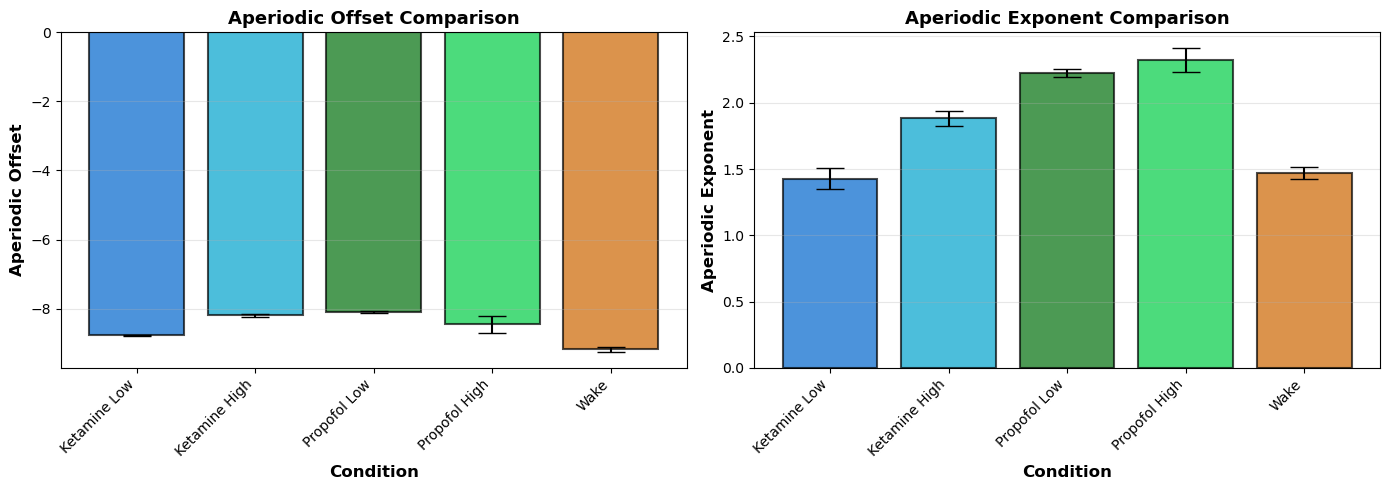

In [15]:
# Plot 2: Bar plots for Offset and Exponent separately
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prepare data for bar plots
offsets_mean = [aps[:, 0].mean() for aps in aps_list]
offsets_std = [aps[:, 0].std() for aps in aps_list]
exponents_mean = [aps[:, 1].mean() for aps in aps_list]
exponents_std = [aps[:, 1].std() for aps in aps_list]

x_pos = np.arange(len(labels))

# Offset bar plot
axes[0].bar(x_pos, offsets_mean, yerr=offsets_std, color=colors,
            alpha=0.7, edgecolor='black', linewidth=1.5, capsize=10)
axes[0].set_xlabel('Condition', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Aperiodic Offset', fontsize=12, fontweight='bold')
axes[0].set_title('Aperiodic Offset Comparison', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels, rotation=45, ha='right')
axes[0].grid(True, alpha=0.3, axis='y')

# Exponent bar plot
axes[1].bar(x_pos, exponents_mean, yerr=exponents_std, color=colors,
            alpha=0.7, edgecolor='black', linewidth=1.5, capsize=10)
axes[1].set_xlabel('Condition', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Aperiodic Exponent', fontsize=12, fontweight='bold')
axes[1].set_title('Aperiodic Exponent Comparison', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

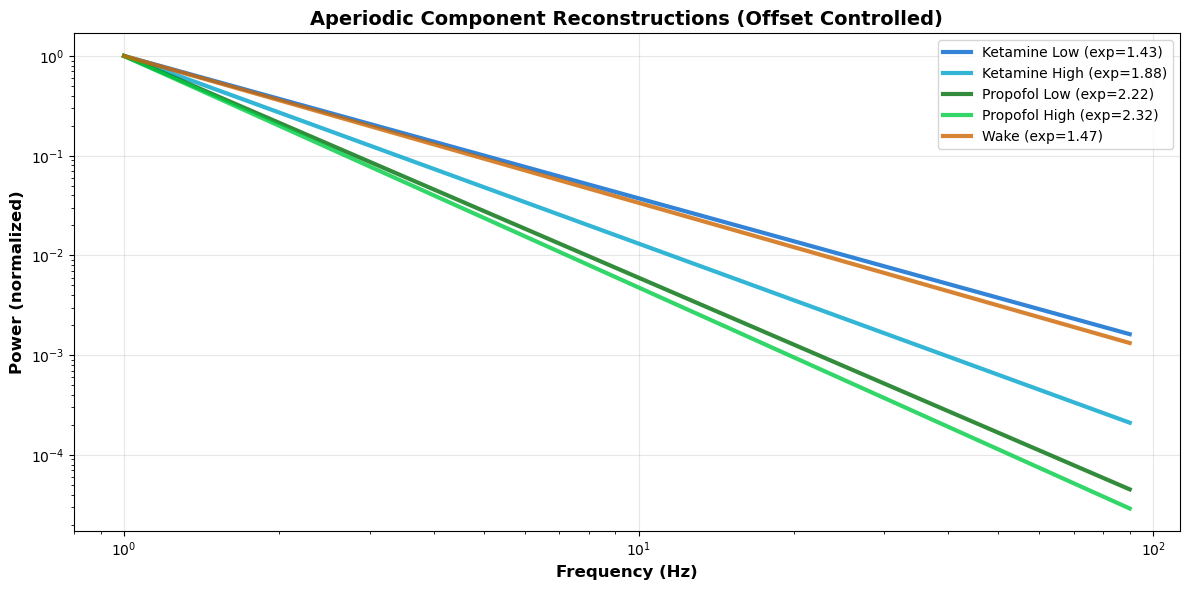

In [16]:
# Plot 3: Aperiodic component reconstructions
fig, ax = plt.subplots(figsize=(12, 6))

# Generate frequency range for reconstruction (log-spaced)
freqs_log = np.logspace(np.log10(fit_range[0]), np.log10(fit_range[1]), 500)

for aps, label, color in zip(aps_list, labels, colors):
    # Calculate mean aperiodic parameters
    mean_offset = aps[:, 0].mean()
    mean_exponent = aps[:, 1].mean()

    # Reconstruct aperiodic component: 10^offset * (1/f^exponent)
    # Setting offset to 0 for better comparison of exponents
    aperiodic_fit = np.zeros_like(freqs_log)
    for i, freq in enumerate(freqs_log):
        aperiodic_fit[i] = 10**(0 - mean_exponent * np.log10(freq))

    ax.loglog(freqs_log, aperiodic_fit, linewidth=3, color=color,
              label=f'{label} (exp={mean_exponent:.2f})', alpha=0.8)

ax.set_xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
ax.set_ylabel('Power (normalized)', fontsize=12, fontweight='bold')
ax.set_title('Aperiodic Component Reconstructions (Offset Controlled)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11) Periodic Components (Oscillations)

In [17]:
# Define frequency bands of interest for anesthesia research
bands = Bands({
    'delta': [1, 4],      # Deep sleep, anesthesia
    'theta': [4, 8],      # Propofol-associated
    'alpha': [8, 13],     # Ketamine-associated
    'beta': [13, 30],     # Arousal, ketamine
    'gamma': [30, 80]     # Higher cognitive function
})

print("\n" + "="*70)
print("PERIODIC PARAMETERS (OSCILLATIONS)")
print("="*70)
print("\nAnalyzing oscillatory peaks in different frequency bands:")
print(f"  Delta: {bands.delta} Hz")
print(f"  Theta: {bands.theta} Hz")
print(f"  Alpha: {bands.alpha} Hz")
print(f"  Beta: {bands.beta} Hz")
print(f"  Gamma: {bands.gamma} Hz\n")


PERIODIC PARAMETERS (OSCILLATIONS)

Analyzing oscillatory peaks in different frequency bands:
  Delta: [1, 4] Hz
  Theta: [4, 8] Hz
  Alpha: [8, 13] Hz
  Beta: [13, 30] Hz
  Gamma: [30, 80] Hz



Alpha Band Analysis:
  Ketamine Low: 1 peaks detected
  Ketamine High: 1 peaks detected
  Propofol Low: 2 peaks detected
  Propofol High: 2 peaks detected
  Wake: 0 peaks detected


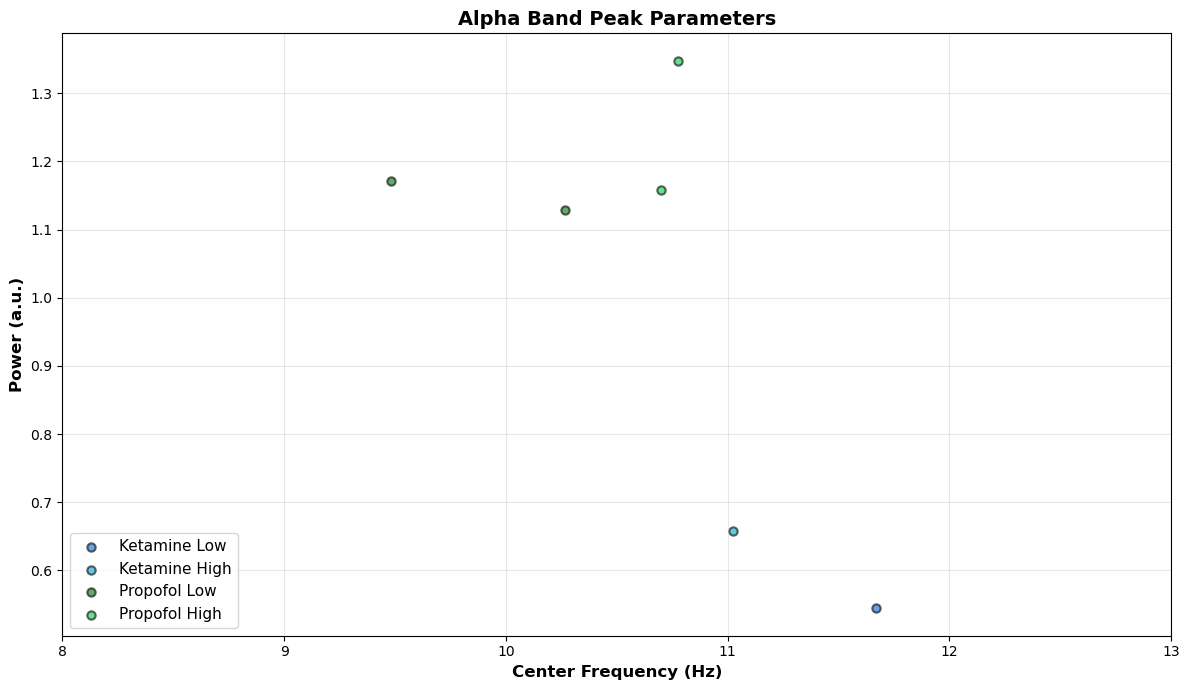

In [18]:
# Extract alpha peaks - Propofol is known to produce robust alpha oscillation; while ketamine suppresses it.
alphas_ketalow = get_band_peak_fg(fg_ketalow, bands.alpha)
alphas_ketahigh = get_band_peak_fg(fg_ketahigh, bands.alpha)
alphas_prolow = get_band_peak_fg(fg_prolow, bands.alpha)
alphas_prohigh = get_band_peak_fg(fg_prohigh, bands.alpha)
alphas_wake = get_band_peak_fg(fg_wake, bands.alpha)

print("Alpha Band Analysis:")
print(f"  Ketamine Low: {len(alphas_ketalow[alphas_ketalow[:, 0] > 0])} peaks detected")
print(f"  Ketamine High: {len(alphas_ketahigh[alphas_ketahigh[:, 0] > 0])} peaks detected")
print(f"  Propofol Low: {len(alphas_prolow[alphas_prolow[:, 0] > 0])} peaks detected")
print(f"  Propofol High: {len(alphas_prohigh[alphas_prohigh[:, 0] > 0])} peaks detected")
print(f"  Wake: {len(alphas_wake[alphas_wake[:, 0] > 0])} peaks detected")

# Create custom visualization of alpha peak parameters
fig, ax = plt.subplots(figsize=(12, 7))

alphas_list = [alphas_ketalow, alphas_ketahigh, alphas_prolow, alphas_prohigh, alphas_wake]

for alphas, label, color in zip(alphas_list, labels, colors):
    # Filter out empty peaks (CF = 0)
    valid_peaks = alphas[alphas[:, 0] > 0]

    if len(valid_peaks) > 0:
        # Extract peak parameters: CF, Power, Bandwidth
        cfs = valid_peaks[:, 0]
        powers = valid_peaks[:, 1]
        bandwidths = valid_peaks[:, 2]

        # Plot with size representing bandwidth
        scatter = ax.scatter(cfs, powers, alpha=0.6,
                           color=color, edgecolors='black', linewidth=1.5,
                           label=label)

ax.set_xlabel('Center Frequency (Hz)', fontsize=12, fontweight='bold')
ax.set_ylabel('Power (a.u.)', fontsize=12, fontweight='bold')
ax.set_title('Alpha Band Peak Parameters', fontsize=14, fontweight='bold')
ax.set_xlim(bands.alpha)
ax.legend(fontsize=11, loc='lower left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()